In [1]:
from random import seed
from algoritmo import juego
from greedy import juego_greedy
from topdown import juego_rec

from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import scipy as sp

from util import time_algorithm

seed(12345)
np.random.seed(12345)

sns.set_theme()

In [2]:
def get_random_array(size: int):
    return np.random.randint(0, 100000, size)

x = np.linspace(100, 10_000, 20).astype(int)

results = time_algorithm(juego, x, lambda s: [get_random_array(s)])

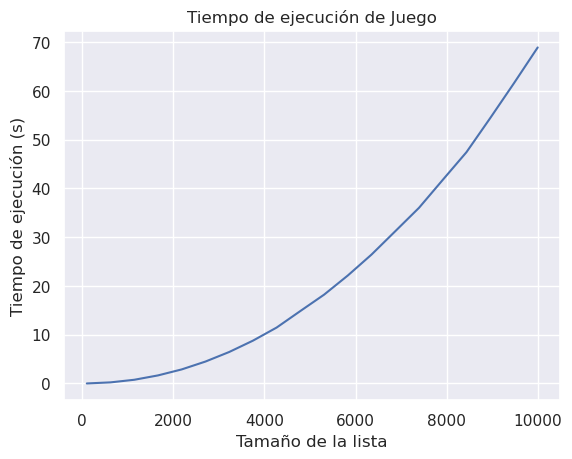

In [3]:
fig, ax = plt.subplots()
ax.plot(x, [results[i] for i in x], label="Medición")
ax.set_title('Tiempo de ejecución de Juego')
ax.set_xlabel('Tamaño de la lista')
ax.set_ylabel('Tiempo de ejecución (s)')
None

In [4]:
f_n2 = lambda x, c1, c2: c1 * (x**2) + c2 

c_n2, pcov = sp.optimize.curve_fit(f_n2, x, [results[n] for n in x])

print(f"c_1 = {c_n2[0]}, c_2 = {c_n2[1]}")
r = np.sum((c_n2[0] * (x**2) + c_n2[1] - [results[n] for n in x])**2)
print(f"Error cuadrático total: {r}")
ecm = r / 20
print(f"Error cuadrático medio: {ecm}")

c_1 = 6.83888689900769e-07, c_2 = -0.6270121321096216
Error cuadrático total: 5.386110227596084
Error cuadrático medio: 0.2693055113798042


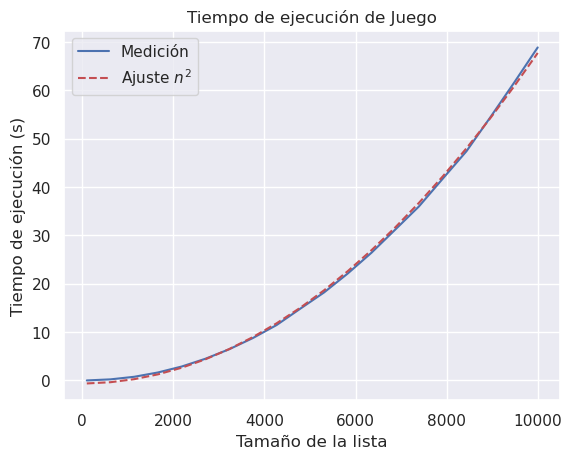

In [5]:
ax.plot(x, [c_n2[0] * (n**2) + c_n2[1] for n in x], 'r--', label="Ajuste $n^2$")
ax.legend()
fig

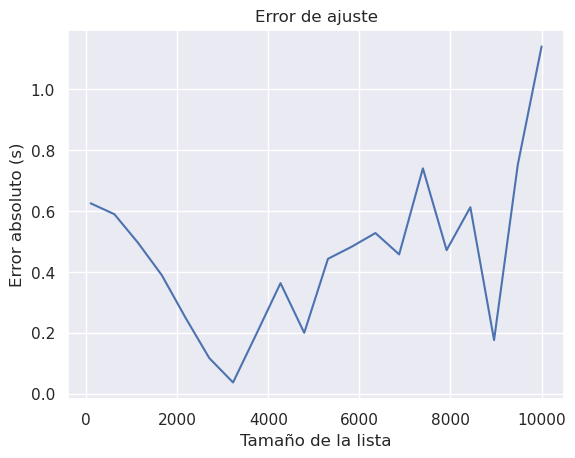

In [6]:
fig, ax = plt.subplots()
errors_n2 = [np.abs(c_n2[0] * (n**2) + c_n2[1] - results[n]) for n in x]
ax.plot(x, errors_n2)
ax.set_title('Error de ajuste')
ax.set_xlabel('Tamaño de la lista')
ax.set_ylabel('Error absoluto (s)')
None

Diferencia entre un ajuste para O(n²) y O(n log n)

In [7]:
f_nlogn = lambda x, c1, c2: c1 * x * np.log(x) + c2 
c_nlogn, _ = sp.optimize.curve_fit(f_nlogn, x, [results[n] for n in x])

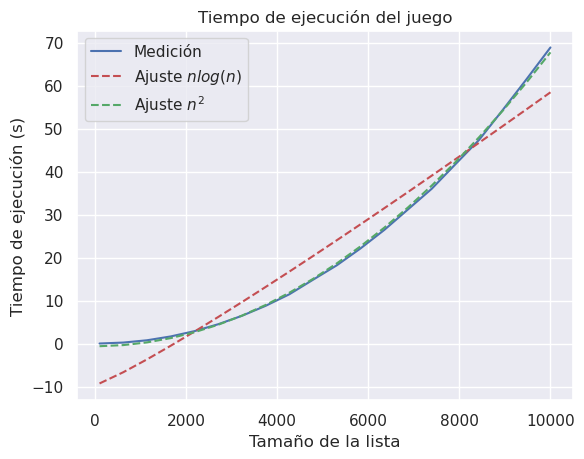

In [8]:
fig, ax = plt.subplots()
ax.plot(x, [results[n] for n in x], label="Medición")
ax.plot(x, [f_nlogn(n, c_nlogn[0], c_nlogn[1]) for n in x], 'r--', label="Ajuste $n log(n)$")
ax.plot(x, [f_n2(n, c_n2[0], c_n2[1]) for n in x], 'g--', label="Ajuste $n^2$")
ax.set_title('Tiempo de ejecución del juego')
ax.set_xlabel('Tamaño de la lista')
ax.set_ylabel('Tiempo de ejecución (s)')
ax.legend()
None

Error cuadrático total para n log(n): 540.1021538258071
Error cuadrático total para n^2: 5.386110227596084


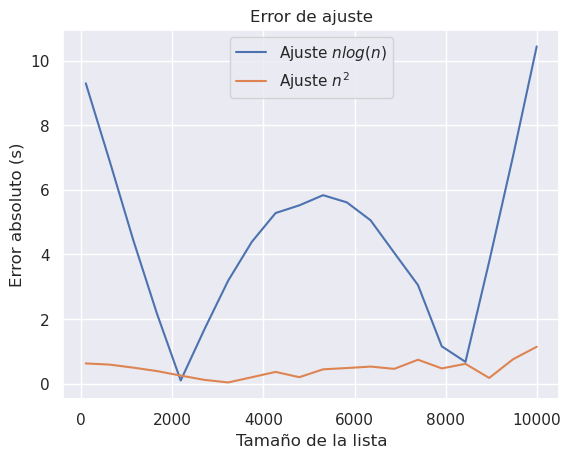

In [9]:
errors_nlogn = [np.abs(c_nlogn[0] * n * np.log(n) + c_nlogn[1] - results[n]) for n in x]

print(f"Error cuadrático total para n log(n): {np.sum(np.power(errors_nlogn, 2))}")
print(f"Error cuadrático total para n^2: {np.sum(np.power(errors_n2, 2))}")

fig, ax = plt.subplots()
ax.plot(x, errors_nlogn, label="Ajuste $n log(n)$")
ax.plot(x, errors_n2, label="Ajuste $n^2$")
ax.set_title('Error de ajuste')
ax.set_xlabel('Tamaño de la lista')
ax.set_ylabel('Error absoluto (s)')
ax.legend()

Comparo este algoritmo con el algoritmo greedy que usaba Sophia

In [10]:
# Se usa el mismo set de datos que antes

results_greedy = time_algorithm(juego_greedy, x, lambda s: [get_random_array(s)])

In [11]:
f_n = lambda x, c1, c2: c1 * x + c2 
c_n, _ = sp.optimize.curve_fit(f_n, x, [results_greedy[n] for n in x])

print(f"Algoritmo Greedy: c_1 = {c_n[0]}, c_2 = {c_n[1]}")
print(f"Algoritmo Programación Dinámica: c_1 = {c_n2[0]}, c_2 = {c_n2[1]}")

Algoritmo Greedy: c_1 = 4.908929079145886e-07, c_2 = 0.0001888235543059682
Algoritmo Programación Dinámica: c_1 = 6.83888689900769e-07, c_2 = -0.6270121321096216


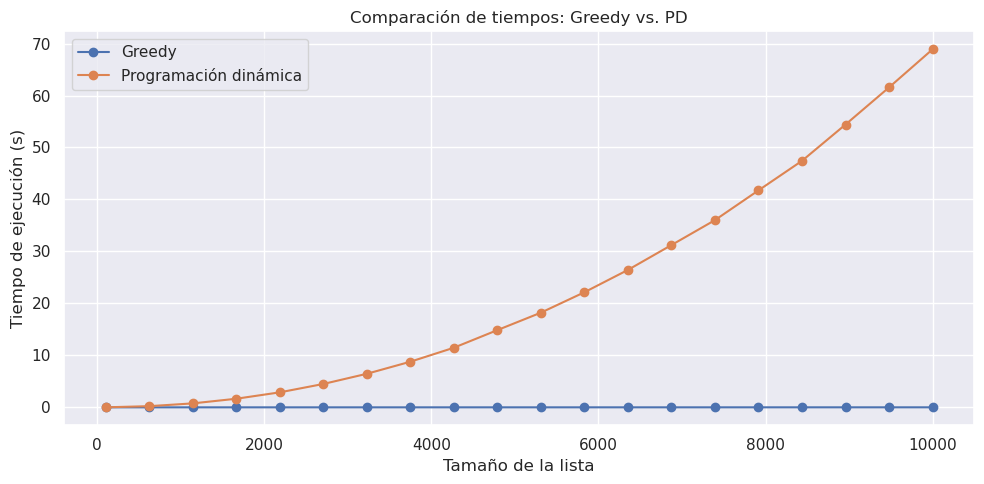

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(x, [results_greedy[n] for n in x], "o-", label="Greedy")
ax.plot(x, [results[n] for n in x], "o-", label="Programación dinámica")

ax.set_xlabel("Tamaño de la lista")
ax.set_ylabel("Tiempo de ejecución (s)")
ax.set_title("Comparación de tiempos: Greedy vs. PD")
ax.legend()

plt.tight_layout()
None

Comparo el algoritmo con Programación Dinámica y tabulación frente a uno Topdown (recursivo) y sin memoization

In [ ]:
# Por temas de lo que demora el algoritmo exponencial, nos vemos obligados a reducir el set
x = np.array([5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 30, 33, 36, 39, 42, 45, 47, 50])

results = time_algorithm(juego, x, lambda s: [get_random_array(s)])
results_2n = time_algorithm(juego_rec, x, lambda s: [get_random_array(s)])

In [ ]:
f_2n = lambda x, c1, c2: c1 * (2**x) + c2
c_2n, _ = sp.optimize.curve_fit(f_2n, x, [results_2n[n] for n in x])
c_n2, _ = sp.optimize.curve_fit(f_n2, x, [results[n] for n in x])

print(f"Algoritmo TopDown: c_1 = {c_2n[0]}, c_2 = {c_2n[1]}")
print(f"Algoritmo Programación Dinámica: c_1 = {c_n2[0]}, c_2 = {c_n2[1]}")

Algoritmo TopDown: c_1 = 1.8932188808072847e-14, c_2 = 0.5879621782557888
Algoritmo Programación Dinámica: c_1 = 5.698649430119218e-07, c_2 = 6.108062167220485e-05


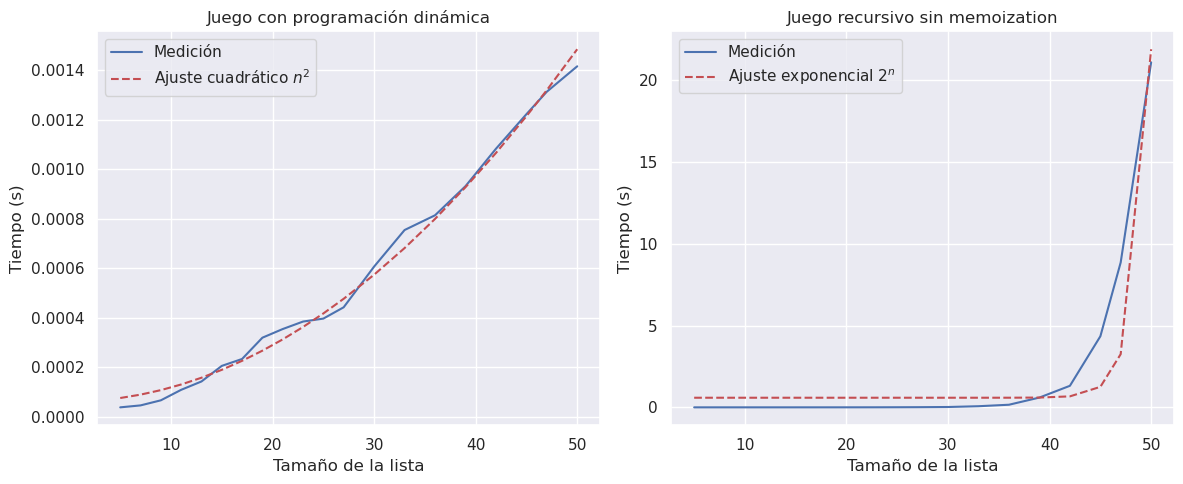

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Algoritmo BottomUp con tabulacion
axs[0].plot(x, [results[n] for n in x], label="Medición")
axs[0].plot(x, [f_n2(n, *c_n2) for n in x], "r--", label="Ajuste cuadrático $n^2$")
axs[0].set_title("Juego con programación dinámica")
axs[0].set_xlabel("Tamaño de la lista")
axs[0].set_ylabel("Tiempo (s)")
axs[0].legend()

# Algoritmo TopDown exponencial
axs[1].plot(x, [results_2n[n] for n in x], label="Medición")
axs[1].plot(x, [f_2n(n, *c_2n) for n in x], "r--", label="Ajuste exponencial $2^n$")
axs[1].set_title("Juego recursivo sin memoization")
axs[1].set_xlabel("Tamaño de la lista")
axs[1].set_ylabel("Tiempo (s)")
axs[1].legend()

plt.tight_layout()
None


Error cuadrático total O(n^2): 4.697737743273033e-09
Error cuadrático total O(2^n): 0.010238971025057369


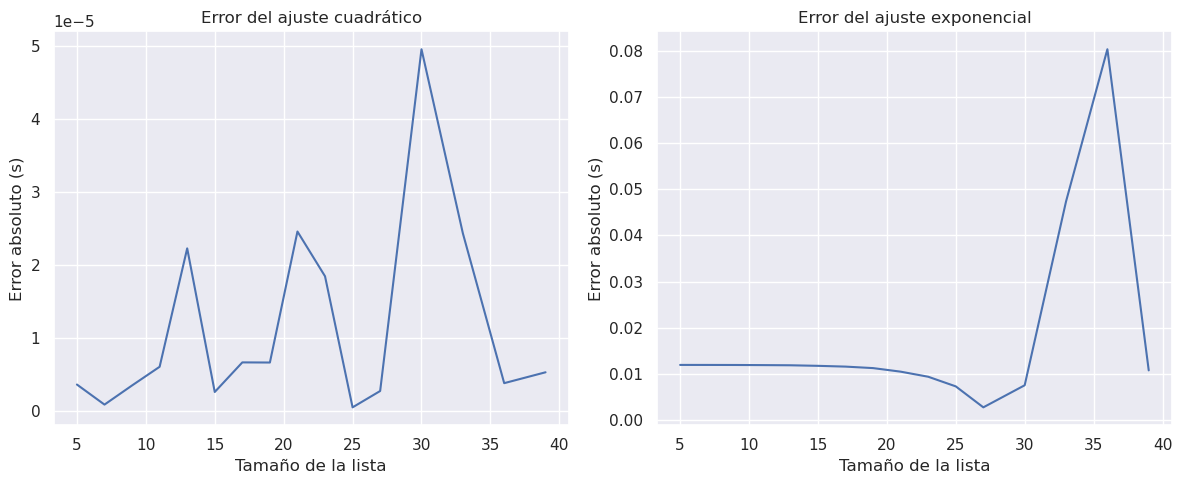

In [16]:

errors_n2 = np.array([f_n2(n, *c_n2) - results[n] for n in x])

errors_2n = np.array([f_2n(n, *c_2n) - results_2n[n] for n in x])

print(f"Error cuadrático total O(n^2): {np.sum(errors_n2**2)}")
print(f"Error cuadrático total O(2^n): {np.sum(errors_2n**2)}")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(x, np.abs(errors_n2))
axs[0].set_title("Error del ajuste cuadrático")
axs[0].set_xlabel("Tamaño de la lista")
axs[0].set_ylabel("Error absoluto (s)")

axs[1].plot(x, np.abs(errors_2n))
axs[1].set_title("Error del ajuste exponencial")
axs[1].set_xlabel("Tamaño de la lista")
axs[1].set_ylabel("Error absoluto (s)")

plt.tight_layout()
None
